In [1]:
import warnings

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
from sklearn import svm
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import Lasso, LogisticRegression, RidgeClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils import shuffle as sk_shuffle
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC_patient_split,
    find_all_indices,
    get_freqs,
    hot_coding,
    visualize_Category_hist,
)
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient, color_palette_full

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
# set prints off
mask.prints = False

## Contents

- Data loading
- Train and test split
- Data augmentation for training data
- Masking and IIVV selection
- Models tuning (RF, SVM, LR, ...)
- SVM kernel model tuning


Interesting: [plot-svm-kernels](https://scikit-learn.org/stable/auto_examples/svm/plot_svm_kernels.html#rbf-kernel)

### Data loading

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

Healthy vs. cancer

Healthy: 89 entries
Cancer: 91 entries


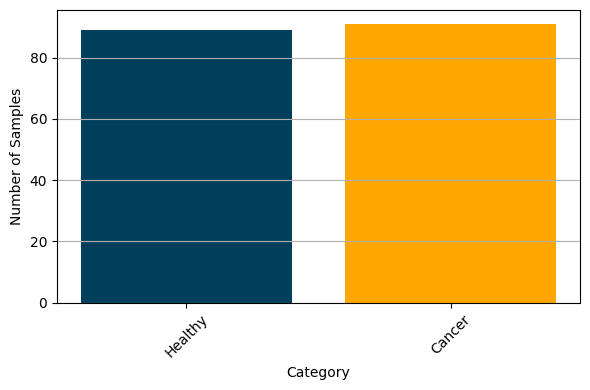

Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(180, 31, 7728) (180, 2) (180,)


In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]
    target_num_augmentation = 150


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
    target_num_augmentation = 150

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]
    target_num_augmentation = 100

visualize_Category_hist(labels)
Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

### Train and test split

In [6]:
random_state = 0
n_folds = 5


def generate_folds(Case, n_folds, random_state):
    unique_patients = np.unique(Case)
    np.random.seed(random_state)

    # Check if Y is in one-hot encoding
    if len(Y.shape) == 1 or Y.shape[1] == 1:
        raise ValueError("Labels (Y) must be in one-hot encoding format")
    # Custom splitting to ensure 70/30 ratio
    patient_indices = np.arange(len(unique_patients))
    np.random.shuffle(patient_indices)

    # Split these indices into n_folds
    fold_size = len(patient_indices) // n_folds
    folds = []

    for i in range(n_folds):
        if i == n_folds - 1:
            # Last fold gets all remaining patients
            test_indices = patient_indices[i * fold_size :]
        else:
            test_indices = patient_indices[i * fold_size : (i + 1) * fold_size]
        # Training indices are all other indices
        train_indices = np.setdiff1d(patient_indices, test_indices)
        folds.append((train_indices, test_indices))

    return folds


folds = generate_folds(Case, n_folds, random_state)

### Data augmentation for training data

- If you want, you can set the SNR in dB here using the variable `snr_db`

In [7]:
snr_db = 30  # dB


def add_noise_2d(signal, snr_db):
    signal_power = np.nanmean(signal**2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear
    noise = np.sqrt(noise_power) * np.random.normal(size=signal.shape)
    return signal + noise


def select_cat_data(X, Y, select: int):
    """
    Get all indices of a single category
    """
    matches = np.all(Y == select, axis=1)
    idxs = np.where(matches)[0]

    return X[idxs, ...], idxs


def data_augmentation(X, Y, tar_num, snr_db, shuffle_data=True, random_state=42):
    if len(Y.shape) == 2:
        cats = np.unique(Y, axis=0)
    else:
        cats = np.unique(Y)
    X_aug = list()
    Y_aug = list()

    for selected_cat in cats:
        # print("Cat:", selected_cat)
        X_select, idxs = select_cat_data(X, Y, selected_cat)
        aug_num = tar_num - len(idxs)
        aug_idxs = np.random.randint(0, len(idxs), size=aug_num)

        print(f"There are {len(idxs)} available samples, {aug_num} will be created.")

        for Xs in X_select:
            X_aug.append(Xs)
            Y_aug.append(selected_cat)

        # augmentation:
        for aug_idx in aug_idxs:
            Xs_noisy = add_noise_2d(X_select[aug_idx], snr_db)
            X_aug.append(Xs_noisy)
            Y_aug.append(selected_cat)
    X_aug = np.array(X_aug)
    Y_aug = np.array(Y_aug)
    if shuffle_data:
        X_aug, Y_aug = sk_shuffle(X_aug, Y_aug, random_state=random_state)

    return X_aug, Y_aug

**The data augmentation is implemented here and will be called during the 5-fold cross validation!**

### Masking and IIVV selection

In [8]:
# load frequency selection
tmp = np.load("results/freq_fold_results.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]

Freq_sel = {
    "Top 2": top_freqs_baseline[:2],
    "Top 3": top_freqs_baseline[:3],
    "Top 5": top_freqs_baseline[:5],
    "Top 12": top_freqs_baseline[:12],
    "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

# load masking selection
Mask_sel = {
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "All": "all",
}

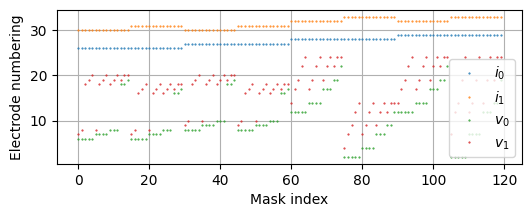

In [9]:
Fsel = "Top 3"
Msel = "Med. a+ ext."


mask.IIVV_mask(Mask_sel[Msel])

## Models tuning

**Tuning results (2025-08-27)**

| Architecture                | ROC AUC | Recall  | F1-score |
|-----------------------------|---------|---------|----------|
| DecisionTreeClassifier      | 0.688687| 0.686796| 0.683795 |
| GradientBoostingClassifier  | 0.843338| 0.785902| 0.785063 |
| **LR**                      | 0.846523| 0.777455| 0.776491 |
| LRscaler                    | 0.816048| 0.756614| 0.755655 |
| **RF**                      | 0.854889| 0.800314| 0.799480 |
| RFscaler                    | 0.854889| 0.800314| 0.799480 |
| RandomForestClassifier      | 0.849772| 0.796042| 0.795347 |
| **SVM**                     | 0.863380| 0.809496| 0.808917 |
| SVMscaler                   | 0.849425| 0.782974| 0.782325 |

    use_models = [
        "SVM",
        "RF",
        "LR",
    ]

In [10]:
from toolbox.model import Model

In [ ]:
stats_df = []
use_models = [
    "SVM",
    "SVMscaler",
    "DecisionTreeClassifier",
    "RandomForestClassifier",
    "GradientBoostingClassifier",
    "RF",
    "RFscaler",
    "LR",
    "LRscaler",
]
output_prints = False

for random_state in range(10):
    print("random_state", random_state)
    folds = generate_folds(Case, n_folds, random_state)
    for fold_idx, (train_patients_idx, test_patients_idx) in enumerate(folds):
        fold = fold_idx + 1

        # Get patient IDs for training and testing
        unique_patients = np.unique(Case)
        train_patients = unique_patients[train_patients_idx]
        test_patients = unique_patients[test_patients_idx]
        if output_prints:
            print("Train patients:", train_patients)
            print("Test patients:", test_patients)
        # Create masks for training and testing samples
        train_mask = np.isin(Case, train_patients)
        test_mask = np.isin(Case, test_patients)
        # Verify split is close to 70/30
        train_pct = train_mask.mean() * 100
        test_pct = test_mask.mean() * 100
        # print(f"Fold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")

        # Count samples and patients in each set
        train_samples = np.sum(train_mask)
        test_samples = np.sum(test_mask)
        train_patient_count = len(train_patients)
        test_patient_count = len(test_patients)

        if output_prints:
            print(f"Fold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")
            print(
                f"  Training: {train_samples} samples from {train_patient_count} patients"
            )
            print(
                f"  Testing:  {test_samples} samples from {test_patient_count} patients"
            )

        # Get training and testing data
        X_train, Y_train = data_augmentation(
            X[train_mask],
            Y[train_mask],
            target_num_augmentation,
            snr_db,
            shuffle_data=True,
            random_state=random_state,
        )

        # unaugmented test data:
        X_test = X[test_mask]
        Y_test = Y[test_mask]

        # here the frequency and IIVV selection is done
        X_train = X_train[:, Freq_sel[Fsel], :]
        X_test = X_test[:, Freq_sel[Fsel], :]
        # IIVV selection
        X_train = X_train[:, :, mask.mask]
        X_test = X_test[:, :, mask.mask]
        # Reshape
        X_train = X_train.reshape(X_train.shape[0], -1)
        X_test = X_test.reshape(X_test.shape[0], -1)

        # ------ Models ------
        for use_model in use_models:
            try:
                pf = Model(
                    use_model,
                    X_train,
                    Y_train,
                    X_test,
                    Y_test,
                    random_state,
                    inverse_mapping,
                    fold,
                    Msel,
                    Fsel,
                    class_task,
                )
                stats_df.append(pf)
            except:
                print(
                    "random state:",
                    random_state,
                    "for",
                    use_model,
                    "isn't working.",
                )
        # -----------------

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_model_HPT.csv", index=False)

In [ ]:
df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_model_HPT.csv")

In [15]:
# Suppose df_avg is your averaged DataFrame
metrics = ["ROC AUC", "Recall", "F1-score"]
df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

df_melt = df_avg.melt(
    id_vars=["Architecture"],
    value_vars=metrics,
    var_name="Metric",
    value_name="Score",
)

df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

print("Average performance:\n", df_avg)

Average performance:
                  Architecture   ROC AUC    Recall  F1-score
0      DecisionTreeClassifier  0.688687  0.686796  0.683795
1  GradientBoostingClassifier  0.843338  0.785902  0.785063
2                          LR  0.846523  0.777455  0.776491
3                    LRscaler  0.816048  0.756614  0.755655
4                          RF  0.854889  0.800314  0.799480
5                    RFscaler  0.854889  0.800314  0.799480
6      RandomForestClassifier  0.849772  0.796042  0.795347
7                         SVM  0.863380  0.809496  0.808917
8                   SVMscaler  0.849425  0.782974  0.782325


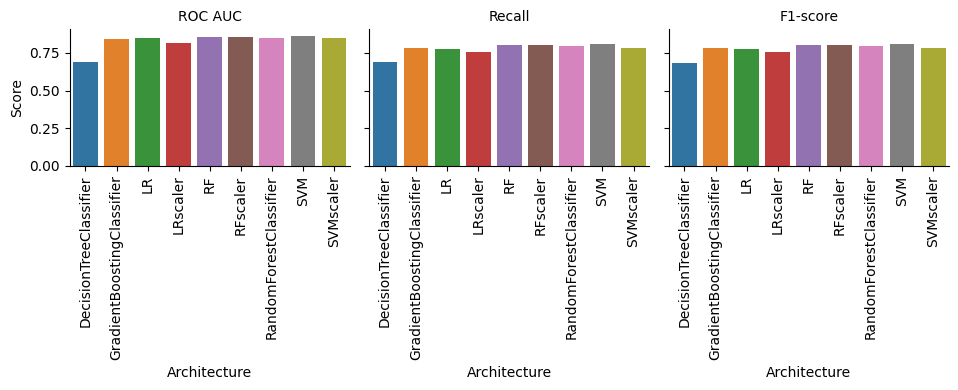

In [14]:
g = sns.catplot(
    data=df_melt,
    x="Architecture",
    y="Score",
    hue="Architecture",
    col="Metric",
    kind="bar",
    height=4,
    aspect=0.8,
)

g.set_titles("{col_name}")
g.set_axis_labels("Architecture", "Score")

# Rotate x tick labels
for ax in g.axes.flat:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.tight_layout()
plt.show()

### SVM kernel model tuning

| Architecture | kernel   | ROC AUC | Recall  | F1-score |
|--------------|----------|---------|---------|----------|
| SVM          | linear   | 0.823760 | 0.753876 | 0.752425 |
| SVM          | poly     | 0.850919 | 0.784960 | 0.784130 |
| SVM          | rbf      | 0.863380 | 0.809496 | 0.808917 |
| SVM          | sigmoid  | 0.813619 | 0.760672 | 0.759394 |
| SVMscaler    | linear   | 0.807068 | 0.740724 | 0.739432 |
| SVMscaler    | poly     | 0.844622 | 0.768655 | 0.765513 |
| SVMscaler    | rbf      | 0.849425 | 0.782974 | 0.782325 |
| SVMscaler    | sigmoid  | 0.838096 | 0.776164 | 0.774922 |

In [16]:
# redefinition of Model() to test different kernels
def Model(
    architecture: str,
    kernel,
    X_train,
    Y_train,
    X_test,
    Y_test,
    random_state,
    inverse_mapping,
    fold,
    Msel,
    Fsel,
    class_task,
):
    if architecture == "SVMscaler":
        print("\nNew Supported vector machine (SVM) with StandardScaler\n")
        m = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(
                SVC(kernel=kernel, probability=True, random_state=random_state)
            ),
        )
    elif architecture == "SVM":
        print("\nSupported vector machine (SVM)\n")
        m = OneVsRestClassifier(
            SVC(kernel=kernel, probability=True, random_state=random_state)
        )

    else:
        raise ValueError(f"Unknown architecture: {architecture}")

    y_score = m.fit(X_train, Y_train).predict_proba(X_test)
    Y_pred = m.predict(X_test)

    if Y_train.shape[1] == 2:
        y_test_tuples = [tuple(row) for row in Y_test.astype(int)]
        y_pred_tuples = [tuple(row) for row in Y_pred.astype(int)]
        y_test_labels = [inverse_mapping[t] for t in y_test_tuples]
        y_pred_labels = [inverse_mapping[t] for t in y_pred_tuples]
        class_labels = list(inverse_mapping.values())
        # confusion matrix
        cm = confusion_matrix(y_test_labels, y_pred_labels, labels=class_labels)

        TP = cm[0, 0]  # true positives (TP)
        TN = cm[1, 1]  # true negatives (TN)
        FN = cm[0, 1]  # false negatives (FN)
        FP = cm[1, 0]  # false positives (FP)

        class_labels = list(inverse_mapping.values())

    score = roc_auc_score(Y_test, y_score)
    recall = recall_score(Y_test, Y_pred, labels=None, average="weighted")
    f1 = f1_score(Y_test, Y_pred, average="weighted")

    print("ROC AUC :", score)
    print("Recall  :", recall)
    print("F1 score:", f1)

    performance = {
        "Architecture": architecture,
        "kernel": kernel,
        "Fold": fold,
        "Random_state": random_state,
        "ROC AUC": score,
        "Recall": recall,
        "F1-score": f1,
        "Mask": Msel,
        "Freq. selection": Fsel,
        "Task": class_task,
    }
    return performance

In [ ]:
stats_df = []
use_models = ["SVM", "SVMscaler"]
kernels = ["linear", "poly", "rbf", "sigmoid"]
output_prints = False

for random_state in range(10):
    print("random_state", random_state)
    folds = generate_folds(Case, n_folds, random_state)
    for fold_idx, (train_patients_idx, test_patients_idx) in enumerate(folds):
        fold = fold_idx + 1
        unique_patients = np.unique(Case)
        train_patients = unique_patients[train_patients_idx]
        test_patients = unique_patients[test_patients_idx]
        if output_prints:
            print("Train patients:", train_patients)
            print("Test patients:", test_patients)
        train_mask = np.isin(Case, train_patients)
        test_mask = np.isin(Case, test_patients)
        train_pct = train_mask.mean() * 100
        test_pct = test_mask.mean() * 100
        train_samples = np.sum(train_mask)
        test_samples = np.sum(test_mask)
        train_patient_count = len(train_patients)
        test_patient_count = len(test_patients)
        if output_prints:
            print(f"Fold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")
            print(
                f"  Training: {train_samples} samples from {train_patient_count} patients"
            )
            print(
                f"  Testing:  {test_samples} samples from {test_patient_count} patients"
            )
        X_train, Y_train = data_augmentation(
            X[train_mask],
            Y[train_mask],
            target_num_augmentation,
            snr_db,
            shuffle_data=True,
            random_state=random_state,
        )
        X_test = X[test_mask]
        Y_test = Y[test_mask]
        X_train = X_train[:, Freq_sel[Fsel], :]
        X_test = X_test[:, Freq_sel[Fsel], :]
        X_train = X_train[:, :, mask.mask]
        X_test = X_test[:, :, mask.mask]
        X_train = X_train.reshape(X_train.shape[0], -1)
        X_test = X_test.reshape(X_test.shape[0], -1)

        # ------ Models ------
        for use_model in use_models:
            for kernel in kernels:
                try:
                    pf = Model(
                        use_model,
                        kernel,
                        X_train,
                        Y_train,
                        X_test,
                        Y_test,
                        random_state,
                        inverse_mapping,
                        fold,
                        Msel,
                        Fsel,
                        class_task,
                    )
                    stats_df.append(pf)
                except:
                    print(
                        "random state:",
                        random_state,
                        "for",
                        use_model,
                        "isn't working.",
                    )
        # -----------------

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_SVMkernel_test.csv", index=False)

In [18]:
df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_SVMkernel_test.csv")

In [19]:
# Suppose df_avg is your averaged DataFrame
metrics = ["ROC AUC", "Recall", "F1-score"]
df_avg = df.groupby(["Architecture", "kernel"])[metrics].mean().reset_index()

df_melt = df_avg.melt(
    id_vars=["Architecture", "kernel"],
    value_vars=metrics,
    var_name="Metric",
    value_name="Score",
)

df_avg = df.groupby(["Architecture", "kernel"])[metrics].mean().reset_index()

print("Average performance:\n", df_avg)

Average performance:
   Architecture   kernel   ROC AUC    Recall  F1-score
0          SVM   linear  0.823760  0.753876  0.752425
1          SVM     poly  0.850919  0.784960  0.784130
2          SVM      rbf  0.863380  0.809496  0.808917
3          SVM  sigmoid  0.813619  0.760672  0.759394
4    SVMscaler   linear  0.807068  0.740724  0.739432
5    SVMscaler     poly  0.844622  0.768655  0.765513
6    SVMscaler      rbf  0.849425  0.782974  0.782325
7    SVMscaler  sigmoid  0.838096  0.776164  0.774922


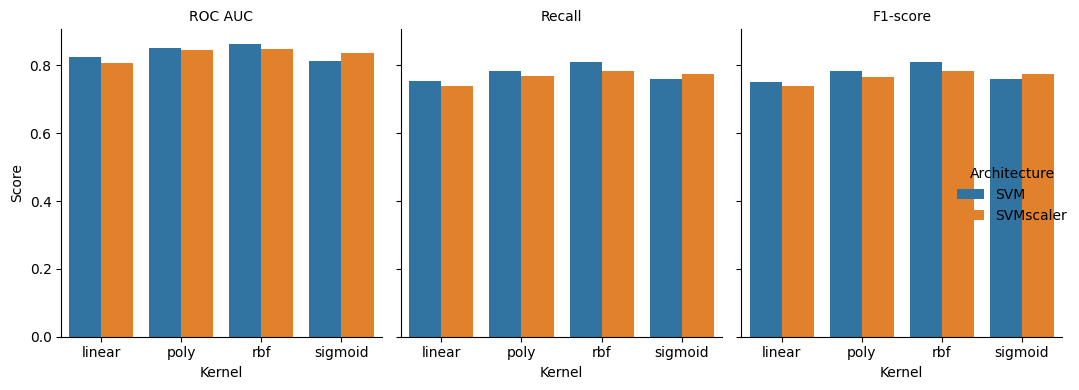

In [20]:
g = sns.catplot(
    data=df_melt,
    x="kernel",
    y="Score",
    hue="Architecture",
    col="Metric",  # works here
    kind="bar",
    height=4,
    aspect=0.8,
)

g.set_titles("{col_name}")
g.set_axis_labels("Kernel", "Score")
plt.tight_layout()
plt.savefig(f"results/hpt_svm_{class_task}.pdf")
plt.show()

___